# Timoshenko Element on a Stepped Shaft Under Distributed Loads: Verification and GCI Mesh Convergence

**Case:** `stepped_shafts / distributed_load / case_distributed_gear_parabolic`
**Study type:** code and solution verification
**Status:** provisional — GCI thresholds to be confirmed

## Questions

1. How far is the Timoshenko FEM solution on the minimal mesh from the
   exact solution of the same equations, for a stepped shaft loaded by
   uniform (gear mesh) and parabolic (user) distributed loads?
2. Which mesh is required for the quantities of interest — the maximum
   resultant deflection and the absolute deviation of the resultant
   bending moment — to be converged, according to the Grid Convergence
   Index (GCI)?
3. Does the GCI estimate actually bound the true discretisation error?
   This can be checked here because the exact solution is known.

## Verification vs. validation

*Verification* establishes that the code solves the equations of the
model correctly; *validation* establishes that the model represents
reality adequately (ASME V&V 10; Roache, 1998). This notebook addresses
verification only: the reference is the exact solution of the same
equations.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from validation._support.figures import shaft_studies as fg
from validation._support.style import use_style
from references.beams import stepped_beam as an
import construction as cd
from axisforge.results.convergence_results.convergence_results import ConvergenceRecord
from axisforge.solvers.machine_elements.shaft.fem_solvers.global_solver.rigid_support import (
    RigidSupportFEMSolver,
)
from axisforge.solvers.machine_elements.shaft.fem_solvers.submodel_solver.lagrange_multipliers import (
    SubmodelSolver,
)
from axisforge.mesh.shaft.mesh_generation.mesh_grade import RefinementFloorReached
from axisforge.solvers.mesh.convergence_solver import (
    MeshConvergenceStudy,
    build_mesh_refinement_result,
)

from validation._support.reports.solver_results import convergence_report as crep
from validation._support.convergence import ResultantView

use_style()                                       # house paper style (style/README.md)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

segs = cd.segments()
system = cd.build_system()
SHAFT = "shaft1"   # change to "shaft2" to repeat the study for the second shaft
shaft_sys = next(ss for ss in system.shafts if ss.name == SHAFT)
SETTINGS = cd.THEORIES["timoshenko/cowper"]
KAPPA = an.kappa_cowper(cd.POISSON)
exact = an.solve_shaft(shaft_sys, segs, KAPPA, cd.SHAFT_LENGTH_MM)
exact_eb = an.solve_shaft(shaft_sys, segs, None, cd.SHAFT_LENGTH_MM)
SUPPORTS = (cd.BALL_POSITION_MM, cd.ROLLER_POSITION_MM)

## 1. Reference solution

The shaft is statically determinate, so the reactions and the bending
moment follow from equilibrium alone (`references/beams/stepped_beam.py`):

$$ M(x) = \sum_k F_k \langle x - x_k\rangle
        + \sum_j \int_{a_j}^{\min(x,\,b_j)} q_j(s)\,(x - s)\,ds, \qquad
   V(x) = -\frac{dM}{dx}, $$

with the reactions among the point forces $F_k$ and the distributed loads
$q_j$ on $[a_j, b_j]$. The kinematics are integrated section by section,

$$ \frac{d\theta}{dx} = \frac{M}{EI(x)}, \qquad
   \frac{dv}{dx} = \theta + \frac{V}{\kappa G A(x)}, $$

with $\theta$ and $v$ continuous at the shoulders and $v(x_A) = v(x_B) = 0$.
Between breakpoints $M$ is a polynomial (degree 2 under the uniform gear
load, degree 4 under the parabolic load), represented and integrated
exactly; the solution is exact to round-off. The second term of
$dv/dx$ is the shear contribution: it always adds to the bending
deflection.

## 2. Timoshenko on the minimal mesh vs. the analytical solution

In [2]:
base = cd.solve(system, SETTINGS)[SHAFT]          # minimal mesh: mandatory nodes only
x = np.asarray(base.x)
xd = np.linspace(0.0, cd.SHAFT_LENGTH_MM, 2001)

def rel_max_err(fem, ref):
    return float(np.max(np.abs(np.asarray(fem) - ref)) / np.max(np.abs(ref)))

pd.DataFrame(
    {"FEM (minimal mesh)": [len(base.x_nodes), base.v_max, base.M_max],
     "analytical": [np.nan, float(np.max(exact.v(xd))), float(np.max(exact.M(xd)))]},
    index=["nodes", "v_res,max / mm", "M_res,max / N·mm"],
).assign(**{"max. nodal error / max|ref|": [np.nan, rel_max_err(base.v, exact.v(x)),
                                             rel_max_err(base.M, exact.M(x))]})

,FEM (minimal mesh),analytical,max. nodal error / max|ref|
nodes,18,NaN,NaN
"v_res,max / mm",0.159337,0.166317,0.0461303
"M_res,max / N·mm",273997,277377,0.374094


**Equilibrium check.** The sum of the FEM reactions must balance the
resultant of every applied load, in both planes (this would expose, for
instance, a gear load silently dropped by the solver):

In [3]:
from axisforge.core.loads import LoadPlane
rows = []
for plane, attr in ((LoadPlane.XY, "xy"), (LoadPlane.XZ, "xz")):
    applied = sum(float(ld.resultant_component(plane)) for ld in shaft_sys.distributed_radial_loads)
    applied += sum(float(ld.component(plane)) for ld in shaft_sys.radial_loads)
    reac = sum(getattr(b, f"Fr_{attr}") for b in base.bearing_nodes)
    rows.append((attr, applied, reac, applied + reac))
pd.DataFrame(rows, columns=["plane", "applied / N", "reactions / N", "residual / N"])

,plane,applied / N,reactions / N,residual / N
0,xy,-1819.85,1819.85,1.46201e-10
1,xz,-7000,7000,4.20187e-10


The FEM result is drawn at its nodes only (filled markers), the exact solution as
a line. The lower panel shows the deviation of the nodal values from the exact
solution, normalised by its maximum: no field between the nodes is drawn.

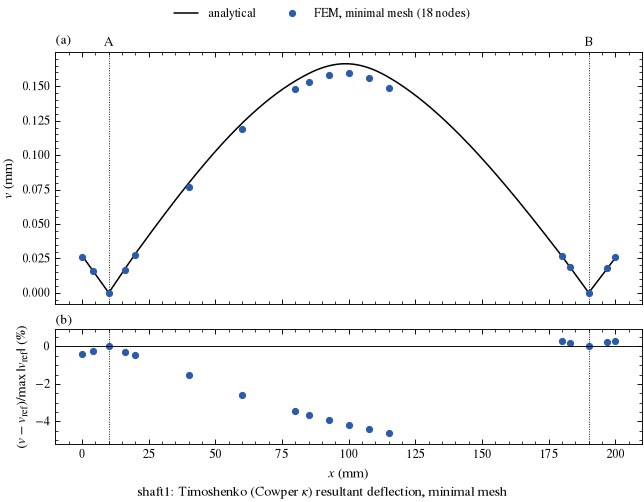

In [4]:
scale = np.max(exact.v(xd))
FEM_BASE = f"FEM, minimal mesh ({len(base.x_nodes)} nodes)"
fig_base = fg.field_comparison(
    [fg.Series(label="analytical", x=xd, y=exact.v(xd), kind="theory"),
     fg.Series(label=FEM_BASE, x=x, y=base.v, kind="numerical")],            # nodal values only
    [fg.Series(label=FEM_BASE, x=x, y=100 * (np.asarray(base.v) - exact.v(x)) / scale, kind="numerical")],
    note=rf"{SHAFT}: Timoshenko (Cowper $\kappa$) resultant deflection, minimal mesh",
    ylabel=r"$v$ (mm)",
    delta_label=r"$(v - v_\mathrm{ref})/\max\vert v_\mathrm{ref}\vert$ (%)",
    supports=SUPPORTS, support_names=("A", "B"),
)

## 3. GCI mesh convergence study

### 3.1 Procedure

The convergence study uses the AxisForge machinery unchanged:

- **Domain:** the supported span $[x_A, x_B] = [10, 190]$ mm, solved as a
  submodel (`SubmodelSolver`), with the displacements and rotations of the
  minimal-mesh global solution prescribed at the two cut nodes.
- **Refinement:** `Grader` bisects every element of the base mesh at each
  grade (`grade_0` = base nodes in the span, `grade_k` = $2^k$ times as many
  elements), so the refinement ratio is constant, $r = 2$.
- **Quantities of interest** (evaluation forms of `convergence_solver.py`),
  computed on the resultant fields
  $v_\mathrm{res} = \sqrt{v_{xy}^2 + v_{xz}^2}$ and
  $M_\mathrm{res} = \sqrt{M_{xy}^2 + M_{xz}^2}$:
    - `v_res:max` — maximum resultant deflection;
    - `M_res:max_minus_mean` — absolute deviation between the maximum and
      the mean of the resultant moment over the span (robust to the shift of
      the moment peak between grades);
    - `M_res:max` — maximum resultant moment (included because, unlike the
      deviation, its exact value is known).
- **GCI** (Roache, 1998), for three consecutive grades $c, m, f$:

$$ p = \frac{\ln\!\left[(f_c - f_m)/(f_m - f_f)\right]}{\ln r}, \qquad
   \mathrm{GCI}_{fm} = \frac{F_s\,|e_{fm}|}{r^p - 1}, \qquad
   e_{fm} = \frac{f_f - f_m}{f_m}. $$

A quantity is converged when $\mathrm{GCI}_{fm}$ and $\mathrm{GCI}_{mc}$ are
both below the threshold.

`SubmodelResult` has no resultant fields, so a thin read-only adapter
exposes `v_res` and `M_res` to `MeshConvergenceStudy`; nothing in AxisForge
is modified.

In [5]:
# --- GCI parameters (to be confirmed by the author) -------------------------
V_REQUESTS = [("v_res", "max")]
M_REQUESTS = [("M_res", "max_minus_mean"), ("M_res", "max")]
V_GCI_THRESHOLD, V_SAFETY_FACTOR = 0.01, 1.25   # 1 %, Fs = 1.25 (asymptotic range)
M_GCI_THRESHOLD, M_SAFETY_FACTOR = 0.02, 3.0    # 2 %, Fs = 3.0  (conservative)
MAX_LEVELS = 5   # grade_0 ... grade_4; grade_5 reaches the refinement floor MESH_MIN_NODE_DIST_MM


x_lo, x_hi = sorted(b.position for b in shaft_sys.bearings)
submodel = SubmodelSolver(x_lo, x_hi)

v_study = MeshConvergenceStudy(V_REQUESTS, gci_threshold=V_GCI_THRESHOLD,
                               safety_factor=V_SAFETY_FACTOR)
m_study = MeshConvergenceStudy(M_REQUESTS, gci_threshold=M_GCI_THRESHOLD,
                               safety_factor=M_SAFETY_FACTOR)
v_rec = v_study.new_record("span_v_res", x_lo, x_hi)
m_rec = m_study.new_record("span_M_res", x_lo, x_hi)

grades: dict[str, ResultantView] = {}
for level in range(MAX_LEVELS):
    grade = f"grade_{level}"
    grades[grade] = ResultantView(submodel.solve(base, shaft_sys, SETTINGS, grade))
    if not v_rec.converged:
        v_study.add_level(v_rec, grade, grades[grade])
    if not m_rec.converged:
        m_study.add_level(m_rec, grade, grades[grade])
    if v_rec.converged and m_rec.converged:
        break

last = grades[grade]
for rec, study in ((v_rec, v_study), (m_rec, m_study)):
    if not rec.converged:
        study.finalize_unconverged(rec, last)

refinement = build_mesh_refinement_result(SHAFT, {v_rec.label: v_rec, m_rec.label: m_rec})

### 3.2 GCI results — deflection

In [6]:
print(crep.interval_block(v_rec))

  Interval 'span_v_res'  [10.000, 190.000] mm  -- CONVERGED
    final mesh: 105 node(s)

level    v_res:max [mm]  GCI_v_res:max
-------  --------------  -------------
grade_0  0.1593369588    --           
grade_1  0.1643082339    --           
grade_2  0.1655457264    0.312023%    
grade_3  0.1658725345    0.088554%    

  Richardson GCI detail (per transition, per metric):
transition                 metric     unit  r         p         delta_m_c  delta_f_m  e_m_c      e_f_m      GCI_m_c    GCI_f_m    f_h0          converged
-------------------------  ---------  ----  --------  --------  ---------  ---------  ---------  ---------  ---------  ---------  ------------  ---------
grade_0->grade_1->grade_2  v_res:max  mm    2.000000  2.006196  4.971e-03  1.237e-03  3.119976%  0.753153%  1.292572%  0.312023%  0.1659558702  False    
grade_1->grade_2->grade_3  v_res:max  mm    2.000000  1.920904  1.237e-03  3.268e-04  0.753153%  0.197413%  0.337846%  0.088554%  0.1659898129  True     

  Ric

### 3.3 GCI results — bending moment

In [7]:
print(crep.interval_block(m_rec))

  Interval 'span_M_res'  [10.000, 190.000] mm  -- NOT CONVERGED (stopped after 5 level(s))
    final mesh: 209 node(s)

level    M_res:max_minus_mean [N.mm]  M_res:max [N.mm]   GCI_M_res:max_minus_mean  GCI_M_res:max
-------  ---------------------------  -----------------  ------------------------  -------------
grade_0  131322.8108620486            273996.9978736383  --                        --           
grade_1  129649.5778889233            276309.3999879324  --                        --           
grade_2  127214.3227094208            276706.2647315077  n/a                       0.089273%    
grade_3  125936.3746057208            276821.7056834840  3.327845%                 0.051341%    
grade_4  125260.9479211277            276844.3466293549  1.803657%                 0.005986%    

  Richardson GCI detail (per transition, per metric):
transition                 metric                unit  r         p         delta_m_c   delta_f_m   e_m_c       e_f_m       GCI_m_c    GCI_f_m    f

## 4. Does the GCI bound the true error?

For each quantity with a known exact value, the true relative error of the
fine grade, $|f_f - f_\mathrm{exact}|/|f_\mathrm{exact}|$, is compared with
the GCI estimate $\mathrm{GCI}_{fm}$ of the same transition, and the
Richardson-extrapolated value $f_{h0}$ is compared with the exact value.

**Richardson extrapolation.** Assuming $f(h) = f_0 + C\,h^p$ in the asymptotic
range, the three grades give the mesh-independent estimate from the finest
pair:

$$ f_{h0} = f_f + \frac{f_f - f_m}{r^p - 1}. $$

**Admissibility.** The GCI and $f_{h0}$ are defined only for $p > 0$. A
transition with $0 < (f_c - f_m)/(f_m - f_f) \le 1$ (differences between grades
not decreasing) has $p \le 0$, is outside the asymptotic range and is reported
as `n/a`, not converged, in the tables of Section 3.

In [8]:
exact_values = {
    "v_res:max": float(np.max(exact.v(np.linspace(x_lo, x_hi, 180_001)))),
    "M_res:max": float(np.max(exact.M(np.linspace(x_lo, x_hi, 180_001)))),
}
rows = []
for rec in (v_rec, m_rec):
    for i, gci_dict in enumerate(rec.gci_history):
        f_c, f_m, f_f = (rec.point_metrics_history[i + k] for k in range(3))
        for name, gci in gci_dict.items():
            if name not in exact_values or not hasattr(gci, "p"):
                continue
            f_ex = exact_values[name]
            rows.append({
                "metric": name,
                "transition": f"{rec.levels[i]}→{rec.levels[i + 2]}",
                "p": gci.p,
                "GCI_fm / %": 100 * gci.GCI_f_m,
                "true error f_f / %": 100 * abs(f_f[name] - f_ex) / abs(f_ex),
                "GCI bounds error": 100 * gci.GCI_f_m >= 100 * abs(f_f[name] - f_ex) / abs(f_ex),
                "f_h0 (Richardson)": gci.f_h0,
                "exact": f_ex,
                "f_h0 error / %": 100 * abs(gci.f_h0 - f_ex) / abs(f_ex),
            })
gci_check = pd.DataFrame(rows)
gci_check

,metric,transition,p,GCI_fm / %,true error f_f / %,GCI bounds error,f_h0 (Richardson),exact,f_h0 error / %
0,v_res:max,grade_0→grade_2,2.0062,0.312023,0.463878,False,0.165956,0.166317,0.217274
1,v_res:max,grade_1→grade_3,1.9209,0.0885543,0.267381,False,0.16599,0.166317,0.196866
2,M_res:max,grade_0→grade_2,2.54267,0.089273,0.241955,False,276788,277377,0.212312
3,M_res:max,grade_1→grade_3,1.78149,0.0513406,0.200336,False,276869,277377,0.183264
4,M_res:max,grade_2→grade_4,2.35015,0.00598635,0.192174,False,276850,277377,0.190182


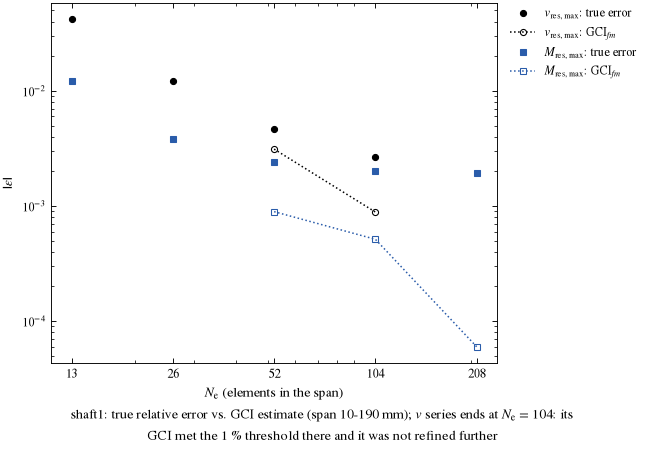

In [9]:
# one colour (a fixed index of the sheet's cycle) and one marker per quantity: true error filled,
# GCI estimate open, so each pair reads as one quantity
def true_error_series(rec, name, label, marker, colour):
    n_el = [len(grades[g].x_nodes) - 1 for g in rec.levels]
    err = [abs(h[name] - exact_values[name]) / exact_values[name] for h in rec.point_metrics_history]
    return fg.Series(label=label, x=n_el, y=err, kind="numerical", marker=marker, kwargs=dict(color=colour))

def gci_series(rec, name, label, marker, colour):
    # GCI is an estimate (Roache), not a measured error: open markers joined by a thin dotted line
    n_el = [len(grades[g].x_nodes) - 1 for g in rec.levels[2:]]
    gci = [g[name].GCI_f_m for g in rec.gci_history]
    return fg.Series(label=label, x=n_el, y=gci, kind="other", linestyle=":", marker=marker,
                     kwargs=dict(markerfacecolor="none", color=colour))

# the v study stops refining once its GCI meets its threshold, so its series ends before M's
v_last = len(grades[v_rec.levels[-1]].x_nodes) - 1
fig_gci = fg.convergence(
    [len(grades[g].x_nodes) - 1 for g in m_rec.levels],
    [true_error_series(v_rec, "v_res:max", r"$v_\mathrm{res,max}$: true error", "o", "C0"),
     gci_series(v_rec, "v_res:max", r"$v_\mathrm{res,max}$: GCI$_{fm}$", "o", "C0"),
     true_error_series(m_rec, "M_res:max", r"$M_\mathrm{res,max}$: true error", "s", "C1"),
     gci_series(m_rec, "M_res:max", r"$M_\mathrm{res,max}$: GCI$_{fm}$", "s", "C1")],
    note=(f"{SHAFT}: true relative error vs. GCI estimate (span {x_lo:.0f}-{x_hi:.0f} mm)"
          + (f"; $v$ series ends at $N_\\mathrm{{e}}$ = {v_last}: its GCI met the "
             f"{100 * V_GCI_THRESHOLD:g} % threshold there and it was not refined further"
             if v_rec.converged and len(v_rec.levels) < len(m_rec.levels) else "")),
    ylabel=r"$\vert\varepsilon\vert$",
    xlabel=r"$N_\mathrm{e}$ (elements in the span)",
    reference_orders={},
)

### 4.1 Error inherited from the base solution

The submodel prescribes, at its two cut nodes, the displacements **and
rotations** of the global solution on the minimal mesh. At a pin support the
rotation is not a boundary condition of the real problem; prescribing the
rotation of a coarse solution imposes its discretisation error on the
submodel. The submodel then converges to a limit that differs from the
exact solution, and the GCI — which measures only the convergence *within*
the submodel — cannot detect that difference.
The figure above shows it for `M_res:max`: the true error decreases up to
grade 2 and then grows again, as the submodel values approach the biased
limit rather than the exact one.

In [10]:
theta_rows = []
for b in base.bearing_nodes:
    for plane in ("xy", "xz"):
        th_fem = getattr(b, f"theta_{plane}")
        th_ex = float(getattr(exact, plane).theta(b.position))
        theta_rows.append((b.label, plane, th_fem, th_ex, 100 * (th_fem / th_ex - 1) if th_ex else np.nan))
display(pd.DataFrame(theta_rows, columns=["bearing", "plane", "θ prescribed (minimal mesh) / rad",
                                          "θ exact / rad", "deviation / %"]))

v_last = v_rec.gci_history[-1]["v_res:max"]
bias_extrap = 100 * (v_last.f_h0 / exact_values["v_res:max"] - 1)
display(Markdown(
    f"Richardson-extrapolated limit of the submodel sequence: **{v_last.f_h0:.6f} mm**; "
    f"exact maximum deflection: **{exact_values['v_res:max']:.6f} mm**; difference "
    f"**{bias_extrap:+.3f} %**. This is the error inherited from the base solution. It is "
    f"below the 1 % threshold here, but it is a systematic bias, not a discretisation error "
    f"of the submodel, and it does not decrease with the submodel grade."
))

,bearing,plane,θ prescribed (minimal mesh) / rad,θ exact / rad,deviation / %
0,shaft1_ball_locating,xy,-0.000684093,-0.00070183,-2.52725
1,shaft1_ball_locating,xz,-0.00254114,-0.0026077,-2.55214
2,shaft1_roller_nonlocating,xy,0.000717449,0.00070183,2.2254
3,shaft1_roller_nonlocating,xz,0.00249238,0.0024427,2.03397


Richardson-extrapolated limit of the submodel sequence: **0.165990 mm**; exact maximum deflection: **0.166317 mm**; difference **-0.197 %**. This is the error inherited from the base solution. It is below the 1 % threshold here, but it is a systematic bias, not a discretisation error of the submodel, and it does not decrease with the submodel grade.

### 4.2 Behaviour of `max_minus_mean`

`max_minus_mean` subtracts the **arithmetic mean of the nodal values**,
not the spatial mean of $M(x)$. On a non-uniform base mesh (element lengths
from 3 to 65 mm here) the nodes are concentrated near the bearings and the
gear, so the nodal mean is a mesh-weighted average that changes with the
node distribution. The quantity converges slowly and with an observed order
below the theoretical one (Section 3.3), and grade 5 could not be used: the
bisection would produce elements shorter than `MESH_MIN_NODE_DIST_MM` (the
refinement floor), where the refinement ratio could no longer be 2. A spatial mean,
$\frac{1}{x_B - x_A}\int M\,dx$ (e.g. trapezoidal), would remove the
dependence on node distribution.

## 5. Production solve on the converged mesh

The converged node sets of both records are merged
(`MeshRefinementResult.all_extra_nodes`) and the whole shaft is re-solved
with them as extra mandatory nodes.

In [11]:
extra = refinement.all_extra_nodes
converged = RigidSupportFEMSolver(SETTINGS).solve(shaft_sys, extra_mandatory=extra)
eb = cd.solve(system, cd.THEORIES["euler_bernoulli"])[SHAFT]   # deflection nodally exact on any mesh
xc = np.asarray(converged.x)

summary = pd.DataFrame(
    {"minimal mesh": [len(base.x_nodes), base.v_max, base.M_max,
                      rel_max_err(base.v, exact.v(x))],
     "converged mesh": [len(converged.x_nodes), converged.v_max, converged.M_max,
                        rel_max_err(converged.v, exact.v(xc))],
     "analytical": [np.nan, exact_values["v_res:max"], exact_values["M_res:max"], np.nan]},
    index=["nodes", "v_res,max / mm", "M_res,max / N·mm", "max. nodal error in v / max|v|"],
)
summary

,minimal mesh,converged mesh,analytical
nodes,18,213,NaN
"v_res,max / mm",0.159337,0.166289,0.166317
"M_res,max / N·mm",273997,277364,277377
max. nodal error in v / max|v|,0.0461303,0.000179887,NaN


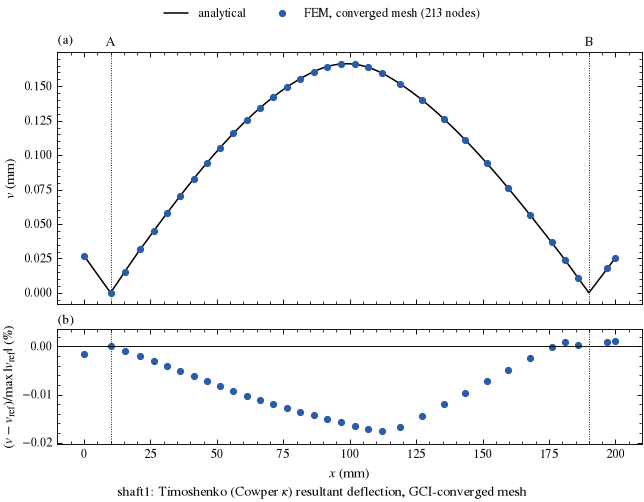

In [12]:
FEM_CONV = f"FEM, converged mesh ({len(converged.x_nodes)} nodes)"
fig_conv = fg.field_comparison(
    [fg.Series(label="analytical", x=xd, y=exact.v(xd), kind="theory"),
     fg.Series(label=FEM_CONV, x=xc, y=converged.v, kind="numerical")],       # nodal values only
    [fg.Series(label=FEM_CONV, x=xc, y=100 * (np.asarray(converged.v) - exact.v(xc)) / np.max(exact.v(xd)),
               kind="numerical")],
    note=rf"{SHAFT}: Timoshenko (Cowper $\kappa$) resultant deflection, GCI-converged mesh",
    ylabel=r"$v$ (mm)",
    delta_label=r"$(v - v_\mathrm{ref})/\max\vert v_\mathrm{ref}\vert$ (%)",
    supports=SUPPORTS, support_names=("A", "B"),
)

## 6. Local convergence on the distributed-load intervals

After the global study, each distributed-load interval is refined on its
own to check the **observed order of convergence** where the load acts.

- **Base solution:** the global solution on the mesh at which `v_res:max`
  converged (Section 3.2). The cut nodes of each interval then receive
  displacements and rotations that are already accurate, so the local
  sequences converge close to the exact values (Section 4.1 shows what happens
  with a coarse base).
- **Intervals:** the parabolic user load and the gear face width.
- **Quantities**, evaluated at the interval centroid (a mandatory node, so it
  is present on every grade) and over the interval:
    - `v_res:at_point` — deflection; the linear Timoshenko element with
      reduced integration gives **p = 2** at the nodes;
    - `M_res:at_point` — bending moment; $M = EI\,d\theta/dx$ is constant within
      each element, hence **p = 1**;
    - `M_res:max_minus_mean` — the quantity of the global study.
- **Grades:** every grade is added (the study is not stopped at the threshold)
  until the next bisection would produce elements shorter than
  `MESH_MIN_NODE_DIST_MM`; the grader then raises `RefinementFloorReached` and
  the loop stops at the previous grade.

In [13]:
LOCAL_REQUESTS = [("v_res", "at_point", "centroid"),
                  ("M_res", "at_point", "centroid"),
                  ("M_res", "max_minus_mean")]
EXPECTED_P = {"v_res:at_point:centroid": 2.0,
              "M_res:at_point:centroid": 1.0,
              "M_res:max_minus_mean": 1.0}
LOCAL_MAX_LEVELS = 8

local_base = RigidSupportFEMSolver(SETTINGS).solve(shaft_sys, extra_mandatory=v_rec.x_final)
intervals = sorted({(ld.x_lo, ld.x_hi) for ld in shaft_sys.distributed_radial_loads})

local_records = {}
for lo, hi in intervals:
    centroid = 0.5 * (lo + hi)                      # symmetric loads: centroid = centre
    study = MeshConvergenceStudy(LOCAL_REQUESTS, gci_threshold=M_GCI_THRESHOLD,
                                 safety_factor=M_SAFETY_FACTOR)
    rec = study.new_record(f"local_[{lo:g},{hi:g}]", lo, hi)
    sub = SubmodelSolver(lo, hi)
    for level in range(LOCAL_MAX_LEVELS):
        try:
            view = ResultantView(sub.solve(local_base, shaft_sys, SETTINGS, f"grade_{level}"))
        except RefinementFloorReached as exc:        # next grade below MESH_MIN_NODE_DIST_MM
            print(f"[{lo:g}, {hi:g}] stopped before grade_{level}: {exc}")
            break
        study.add_level(rec, f"grade_{level}", view, points={"centroid": centroid})
        last_view = view
    if not rec.converged:
        study.finalize_unconverged(rec, last_view)
    local_records[(lo, hi)] = rec

display(Markdown(f"Base for the local studies: global solve on **{len(local_base.x_nodes)} nodes** "
                 f"(the `v_res:max` converged mesh)."))

[40, 80] stopped before grade_5: Grader: 'grade_5' needs bisecting an interval of 0.15625 mm, which would give elements of 0.078125 mm <= MESH_MIN_NODE_DIST_MM = 0.1 mm. Refinement floor reached: stop the grade loop at the previous grade.


[92.5, 107.5] stopped before grade_4: Grader: 'grade_4' needs bisecting an interval of 0.117188 mm, which would give elements of 0.0585938 mm <= MESH_MIN_NODE_DIST_MM = 0.1 mm. Refinement floor reached: stop the grade loop at the previous grade.


Base for the local studies: global solve on **109 nodes** (the `v_res:max` converged mesh).

In [14]:
for (lo, hi), rec in local_records.items():
    print(crep.interval_block(rec))
    print()

  Interval 'local_[40,80]'  [40.000, 80.000] mm  -- CONVERGED
    final mesh: 257 node(s)

level    v_res:at_point:centroid [mm]  M_res:at_point:centroid [N.mm]  M_res:max_minus_mean [N.mm]  GCI_v_res:at_point:centroid  GCI_M_res:at_point:centroid  GCI_M_res:max_minus_mean
-------  ----------------------------  ------------------------------  ---------------------------  ---------------------------  ---------------------------  ------------------------
grade_0  0.1230570283                  191143.2314476957               54962.2895546014             --                           --                           --                      
grade_1  0.1230579180                  193134.1860420461               54431.0850759893             --                           --                           --                      
grade_2  0.1230581409                  194110.8237842486               54089.7227188127             0.000182%                    1.460681%                    3.383085%          

### 6.1 Observed order vs. theoretical order

In [15]:
rows = []
for (lo, hi), rec in local_records.items():
    centroid = 0.5 * (lo + hi)
    exact_at = {"v_res:at_point:centroid": float(exact.v(centroid)),
                "M_res:at_point:centroid": float(exact.M(centroid))}
    for i, gci_dict in enumerate(rec.gci_history):
        f_f = rec.point_metrics_history[i + 2]
        for name, gci in gci_dict.items():
            ok = hasattr(gci, "p")
            rows.append({
                "interval / mm": f"[{lo:g}, {hi:g}]",
                "metric": name,
                "transition": f"{rec.levels[i]}→{rec.levels[i + 2]}",
                "p observed": gci.p if ok else np.nan,
                "p theoretical": EXPECTED_P[name],
                "GCI_fm / %": 100 * gci.GCI_f_m if ok else np.nan,
                "f_fine": f_f[name],
                "exact": exact_at.get(name, np.nan),
                "error f_fine / %": (100 * abs(f_f[name] / exact_at[name] - 1)
                                     if name in exact_at else np.nan),
            })
local_p = pd.DataFrame(rows)
local_p

,interval / mm,metric,transition,p observed,p theoretical,GCI_fm / %,f_fine,exact,error f_fine / %
0,"[40, 80]",v_res:at_point:centroid,grade_0→grade_2,1.99718,2,0.000181586,0.123058,0.123124,0.0531289
1,"[40, 80]",M_res:at_point:centroid,grade_0→grade_2,1.02756,1,1.46068,194111,195101,0.507563
2,"[40, 80]",M_res:max_minus_mean,grade_0→grade_2,0.637963,1,3.38309,54089.7,NaN,NaN
3,"[40, 80]",v_res:at_point:centroid,grade_1→grade_3,1.9993,2,4.53297e-05,0.123058,0.123124,0.0530836
4,"[40, 80]",M_res:at_point:centroid,grade_1→grade_3,1.01317,1,0.73438,194595,195101,0.259546
5,"[40, 80]",M_res:max_minus_mean,grade_1→grade_3,0.841267,1,1.33493,53899.2,NaN,NaN
6,"[40, 80]",v_res:at_point:centroid,grade_2→grade_4,1.99982,2,1.13283e-05,0.123058,0.123124,0.0530723
7,"[40, 80]",M_res:at_point:centroid,grade_2→grade_4,1.00642,1,0.368057,194836,195101,0.136088
8,"[40, 80]",M_res:max_minus_mean,grade_2→grade_4,0.924978,1,0.62154,53798.8,NaN,NaN
9,"[92.5, 107.5]",v_res:at_point:centroid,grade_0→grade_2,2,2,2.04239e-05,0.16615,0.166258,0.0648255


The deflection reaches $p = 2$ and the bending moment $p \to 1$ in both
intervals, as predicted for the linear Timoshenko element. The remaining
offset of the fine-grade values from the exact ones (≈ 0.05 %) is inherited
from the base solution at the cut nodes, not a local discretisation error.
Over the gear face width the bending moment is nearly flat, so
`M_res:max_minus_mean` is a small difference of large numbers (a few kN·mm
against $M \approx 183$ kN·mm): its relative GCI is large and its observed
order is not meaningful there; `M_res:at_point` is the appropriate quantity
for that interval.

## 7. Conclusions

In [16]:
def last_valid(rec, name):
    """Last transition with a real (non-placeholder) GCI for this metric."""
    for g in reversed(rec.gci_history):
        if hasattr(g[name], "p"):
            return g[name]
    return None

def status(rec):
    return "converged" if rec.converged else f"**NOT converged** after {len(rec.levels)} grades"

shear_effect = 100 * (converged.v_max / eb.v_max - 1)
shear_exact = 100 * (np.max(exact.v(xd)) / np.max(exact_eb.v(xd)) - 1)
v_gci = last_valid(v_rec, "v_res:max")
m_gci = last_valid(m_rec, "M_res:max_minus_mean")
mm_gci = last_valid(m_rec, "M_res:max")
last_p = (local_p.dropna(subset=["p observed"])
          .groupby(["interval / mm", "metric"], sort=False).last()["p observed"])
local_summary = "; ".join(f"{iv} `{m}` p = {p:.2f} (theory {EXPECTED_P[m]:g})"
                          for (iv, m), p in last_p.items())
bad = gci_check[~gci_check["GCI bounds error"]]
unbounded_text = "" if bad.empty else " ".join(
    f"In `{r.metric}` ({r.transition}) the true error ({r['true error f_f / %']:.3f} %) exceeds "
    f"the GCI ({r['GCI_fm / %']:.3f} %): the fine grade has already reached the biased limit."
    for _, r in bad.iterrows())
display(Markdown(f"""
1. On the minimal mesh ({len(base.x_nodes)} nodes) the Timoshenko deflection deviates from
   the exact solution by **{100 * rel_max_err(base.v, exact.v(x)):.1f} %**; the reactions balance
   the applied loads (Section 2).
2. `v_res:max`: {status(v_rec)} at {v_rec.levels[-1]} (GCI$_{{fm}}$ = {100 * v_gci.GCI_f_m:.3f} %,
   observed order p = {v_gci.p:.2f}, theoretical 2).
3. `M_res`: {status(m_rec)}. `M_res:max` converges well (last GCI$_{{fm}}$ =
   {100 * mm_gci.GCI_f_m:.3f} %), but `M_res:max_minus_mean` does not reach the 2 % criterion on
   both transitions (last GCI$_{{fm}}$ = {100 * m_gci.GCI_f_m:.2f} %, p = {m_gci.p:.2f}), because
   its nodal mean depends on the node distribution (Section 4.2).
4. The GCI bounds the true error in {int(gci_check["GCI bounds error"].sum())} of {len(gci_check)}
   transitions with a known exact value (Section 4). {unbounded_text} The submodel sequence
   converges to a limit {bias_extrap:+.3f} % away from the exact deflection, an error inherited
   from the rotations prescribed by the coarse base solution (Section 4.1) that the GCI cannot
   detect.
5. On the converged mesh ({len(converged.x_nodes)} nodes, global solve) the deflection error drops
   to **{100 * rel_max_err(converged.v, exact.v(xc)):.4f} %**, and the shear effect relative to
   Euler–Bernoulli is **{shear_effect:+.2f} %** (exact: {shear_exact:+.2f} %).
6. Local convergence on the distributed-load intervals (Section 6), last observed order:
   {local_summary}.
"""))


1. On the minimal mesh (18 nodes) the Timoshenko deflection deviates from
   the exact solution by **4.6 %**; the reactions balance
   the applied loads (Section 2).
2. `v_res:max`: converged at grade_3 (GCI$_{fm}$ = 0.089 %,
   observed order p = 1.92, theoretical 2).
3. `M_res`: **NOT converged** after 5 grades. `M_res:max` converges well (last GCI$_{fm}$ =
   0.006 %), but `M_res:max_minus_mean` does not reach the 2 % criterion on
   both transitions (last GCI$_{fm}$ = 1.80 %, p = 0.92), because
   its nodal mean depends on the node distribution (Section 4.2).
4. The GCI bounds the true error in 0 of 5
   transitions with a known exact value (Section 4). In `v_res:max` (grade_0→grade_2) the true error (0.464 %) exceeds the GCI (0.312 %): the fine grade has already reached the biased limit. In `v_res:max` (grade_1→grade_3) the true error (0.267 %) exceeds the GCI (0.089 %): the fine grade has already reached the biased limit. In `M_res:max` (grade_0→grade_2) the true error (0.242 %) exceeds the GCI (0.089 %): the fine grade has already reached the biased limit. In `M_res:max` (grade_1→grade_3) the true error (0.200 %) exceeds the GCI (0.051 %): the fine grade has already reached the biased limit. In `M_res:max` (grade_2→grade_4) the true error (0.192 %) exceeds the GCI (0.006 %): the fine grade has already reached the biased limit. The submodel sequence
   converges to a limit -0.197 % away from the exact deflection, an error inherited
   from the rotations prescribed by the coarse base solution (Section 4.1) that the GCI cannot
   detect.
5. On the converged mesh (213 nodes, global solve) the deflection error drops
   to **0.0180 %**, and the shear effect relative to
   Euler–Bernoulli is **+4.57 %** (exact: +4.56 %).
6. Local convergence on the distributed-load intervals (Section 6), last observed order:
   [40, 80] `v_res:at_point:centroid` p = 2.00 (theory 2); [40, 80] `M_res:at_point:centroid` p = 1.01 (theory 1); [40, 80] `M_res:max_minus_mean` p = 0.92 (theory 1); [92.5, 107.5] `v_res:at_point:centroid` p = 2.00 (theory 2); [92.5, 107.5] `M_res:at_point:centroid` p = 0.87 (theory 1); [92.5, 107.5] `M_res:max_minus_mean` p = 0.43 (theory 1).


## References

- ASME V&V 10-2019, *Standard for Verification and Validation in
  Computational Solid Mechanics*.
- Roache, P. J. (1998). *Verification and Validation in Computational
  Science and Engineering*. Hermosa Publishers — GCI and Richardson
  extrapolation.
- Celik, I. B. et al. (2008). Procedure for estimation and reporting of
  uncertainty due to discretization in CFD applications. *J. Fluids Eng.*
  130(7), 078001.
- Cowper (1966); Hutchinson (2001) — see notebook 01.